# Data Visualization: StudentPerformanceFactors Dataset

This notebook creates comprehensive visualizations representing the used data in the blockchain anomaly detection project.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

# Set style for better-looking plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

## Load and Prepare Data

In [7]:
# Load the data
df = pd.read_csv('data/StudentPerformanceFactors.csv')
print(f"Dataset shape: {df.shape}")
print(f"Total records: {len(df)}")
print(f"Total features: {len(df.columns)}")

Dataset shape: (6607, 20)
Total records: 6607
Total features: 20


## Explore Data Structure

In [8]:
# Display basic information
print("Data Types:")
print(df.dtypes)
print("\n" + "="*50)
print("\nBasic Statistics:")
print(df.describe())
print("\n" + "="*50)
print("\nFeature List:")
print(df.columns.tolist())

Data Types:
Hours_Studied                  int64
Attendance                     int64
Parental_Involvement          object
Access_to_Resources           object
Extracurricular_Activities    object
Sleep_Hours                    int64
Previous_Scores                int64
Motivation_Level              object
Internet_Access               object
Tutoring_Sessions              int64
Family_Income                 object
Teacher_Quality               object
School_Type                   object
Peer_Influence                object
Physical_Activity              int64
Learning_Disabilities         object
Parental_Education_Level      object
Distance_from_Home            object
Gender                        object
Exam_Score                     int64
dtype: object


Basic Statistics:
       Hours_Studied   Attendance  Sleep_Hours  Previous_Scores  \
count    6607.000000  6607.000000   6607.00000      6607.000000   
mean       19.975329    79.977448      7.02906        75.070531   
std         5

## Create Comprehensive Visualizations

### 1. Data Overview - Feature Distribution

Numeric columns: 7
Categorical columns: 13


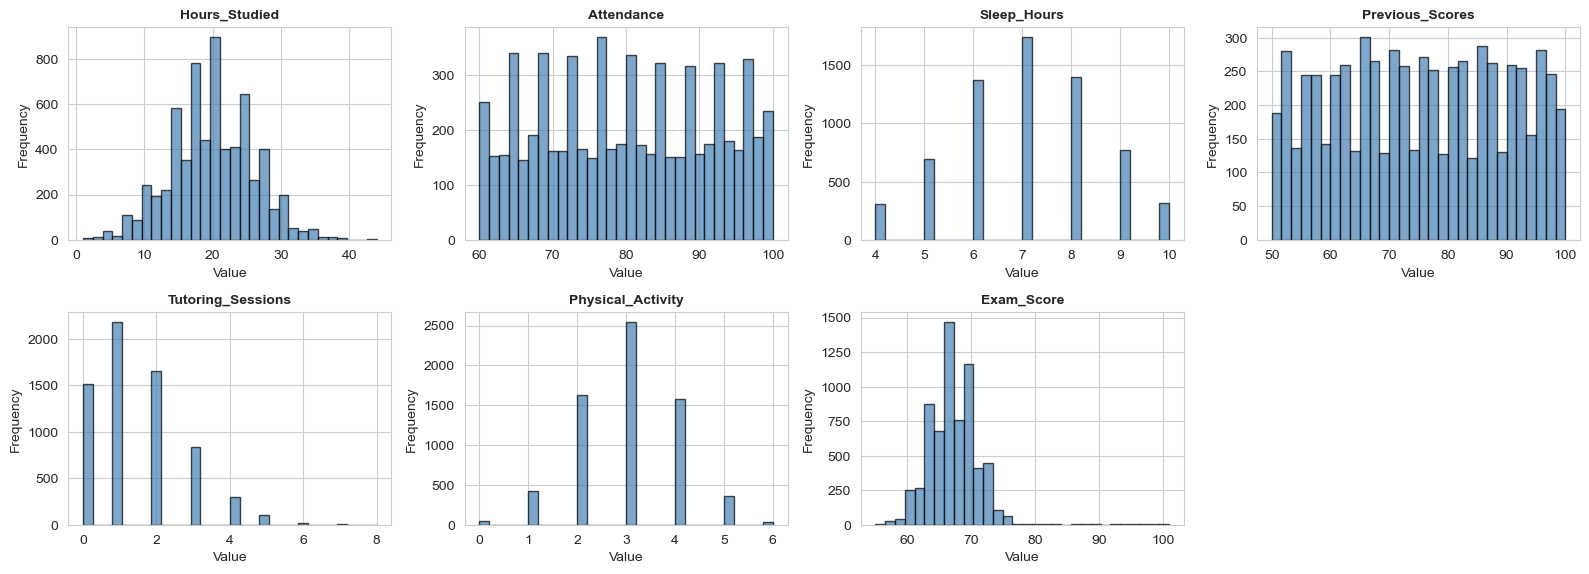

✓ Saved: data_numeric_distributions.png


In [9]:
# Identify numeric and categorical columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print(f"Numeric columns: {len(numeric_cols)}")
print(f"Categorical columns: {len(categorical_cols)}")

# Create visualization for numeric features
fig, axes = plt.subplots(5, 4, figsize=(16, 14))
axes = axes.flatten()

for idx, col in enumerate(numeric_cols):
    axes[idx].hist(df[col], bins=30, color='steelblue', alpha=0.7, edgecolor='black')
    axes[idx].set_title(f'{col}', fontsize=10, fontweight='bold')
    axes[idx].set_xlabel('Value')
    axes[idx].set_ylabel('Frequency')

# Hide unused subplots
for idx in range(len(numeric_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig('outputs/data_numeric_distributions.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: data_numeric_distributions.png")

### 2. Categorical Features Distribution

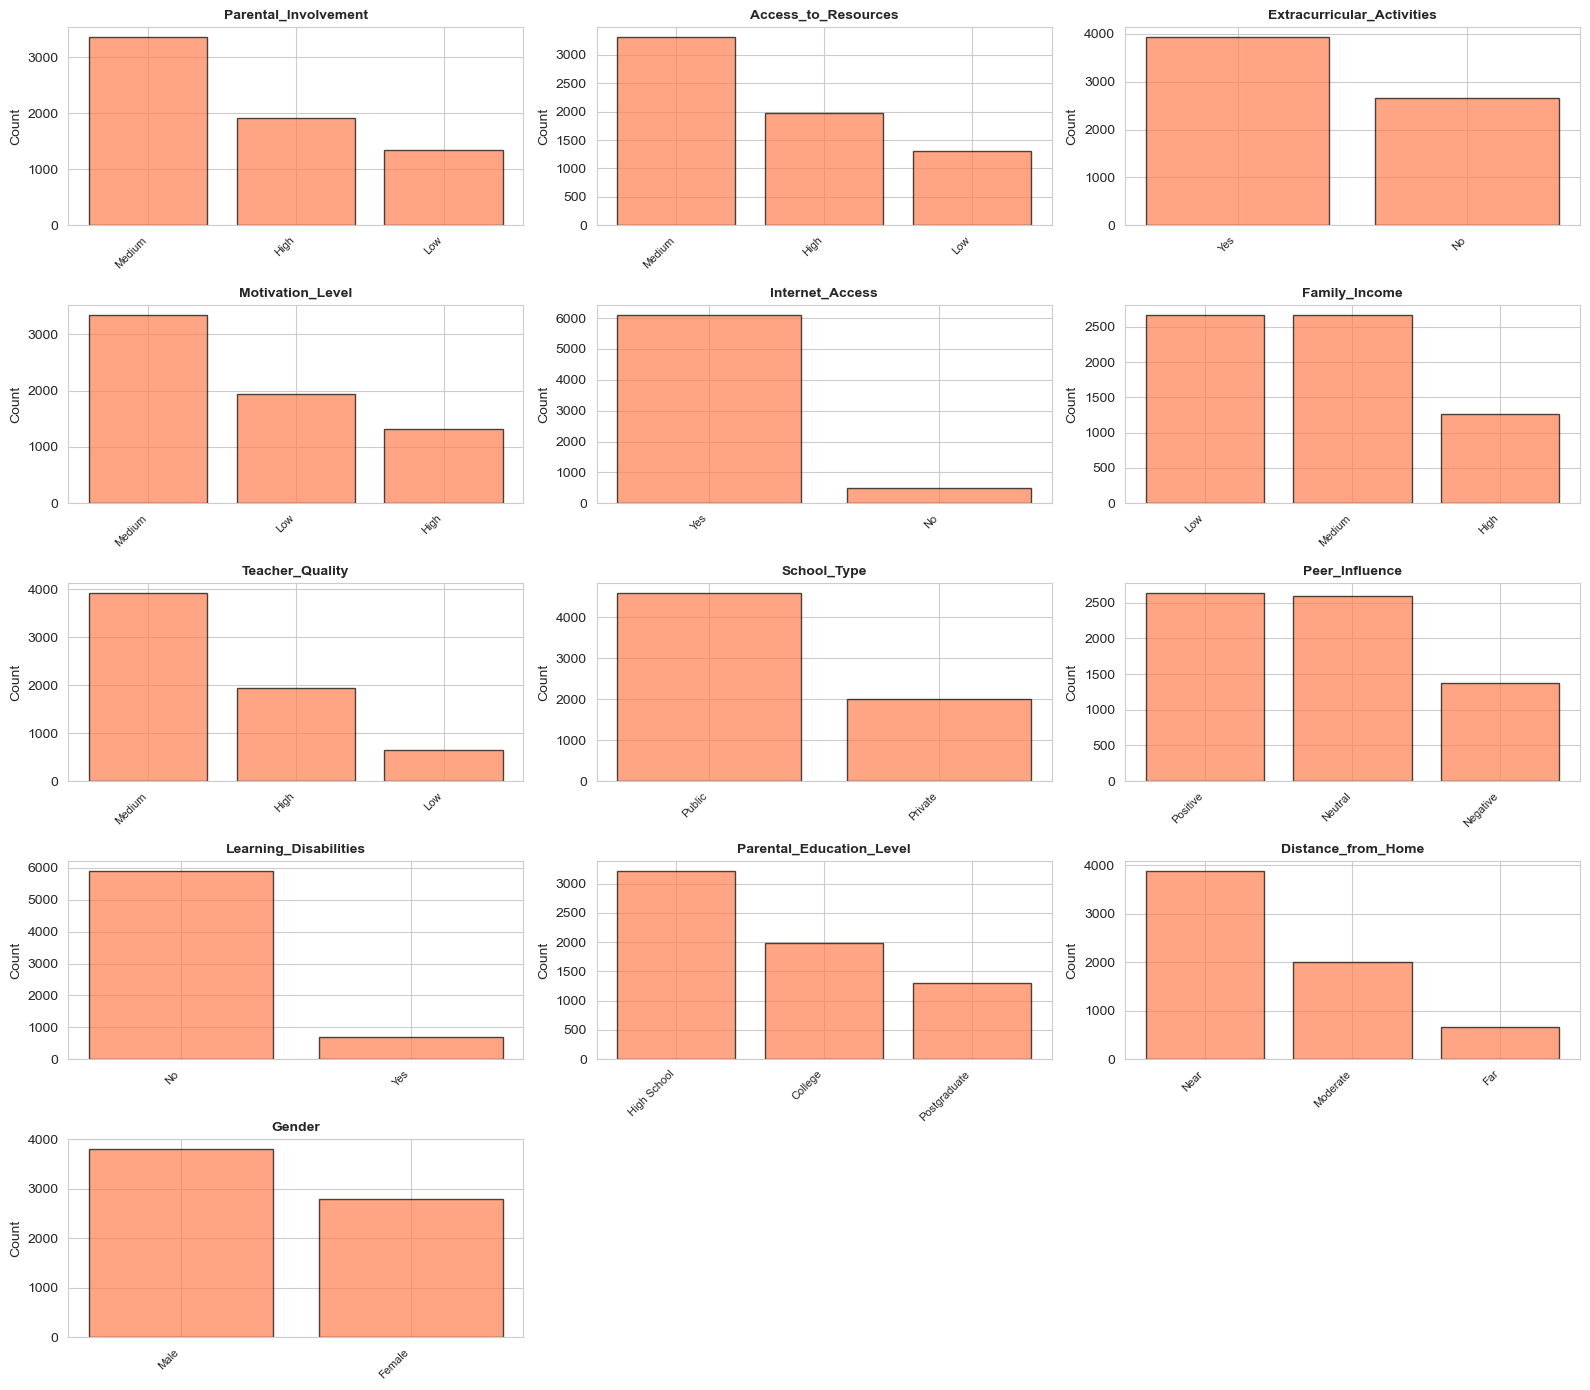

✓ Saved: data_categorical_distributions.png


In [11]:
# Create visualization for categorical features
fig, axes = plt.subplots(5, 3, figsize=(16, 14))
axes = axes.flatten()

for idx, col in enumerate(categorical_cols):
    value_counts = df[col].value_counts()
    axes[idx].bar(range(len(value_counts)), value_counts.values, color='coral', alpha=0.7, edgecolor='black')
    axes[idx].set_xticks(range(len(value_counts)))
    axes[idx].set_xticklabels(value_counts.index, rotation=45, ha='right', fontsize=8)
    axes[idx].set_title(f'{col}', fontsize=10, fontweight='bold')
    axes[idx].set_ylabel('Count')

# Hide unused subplots
for idx in range(len(categorical_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig('outputs/data_categorical_distributions.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: data_categorical_distributions.png")

### 3. Correlation Heatmap

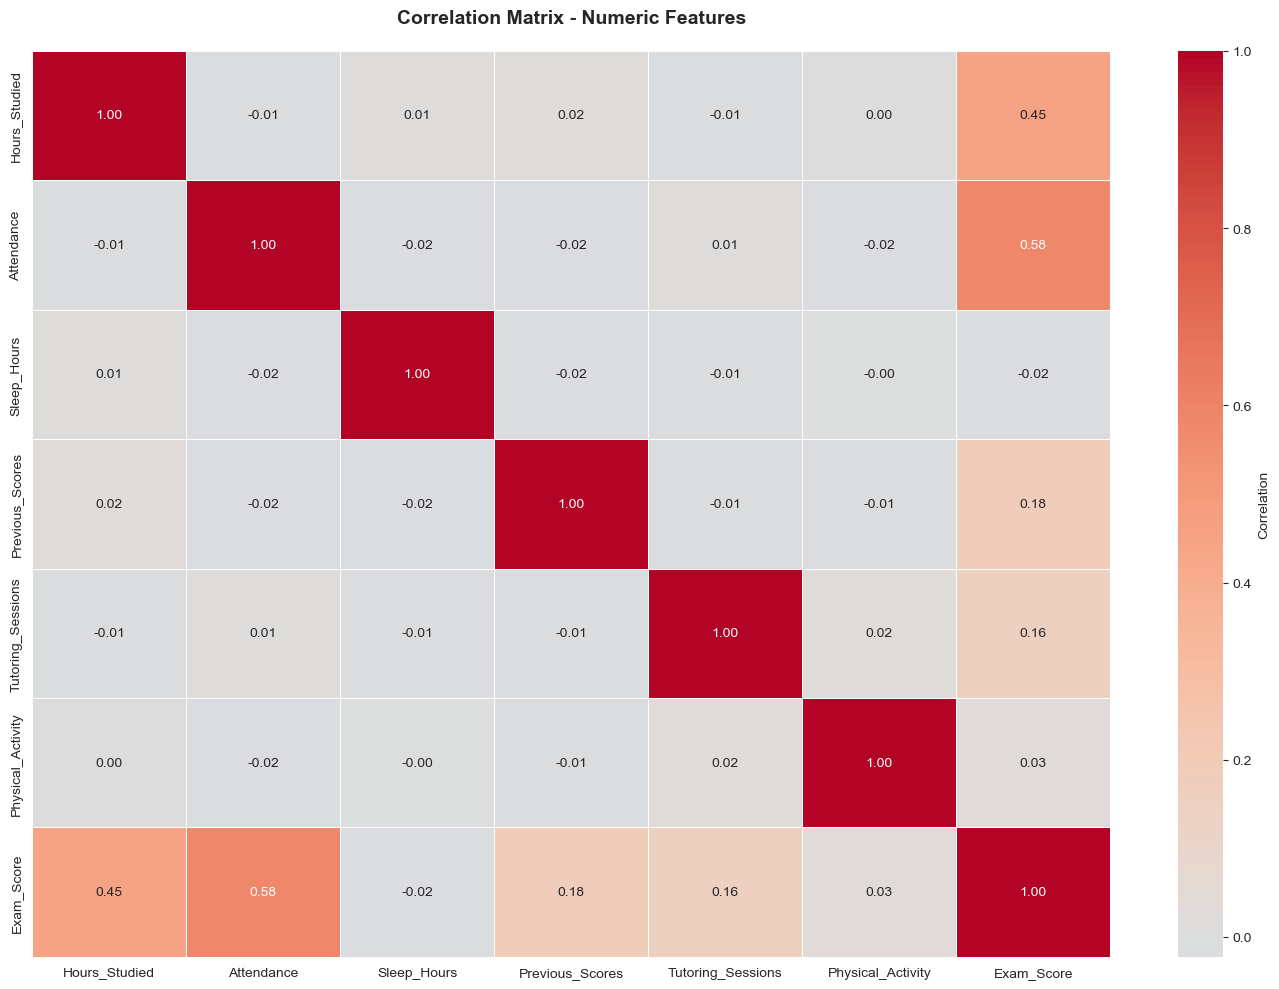

✓ Saved: data_correlation_heatmap.png


In [12]:
# Correlation matrix for numeric features
correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            cbar_kws={'label': 'Correlation'}, linewidths=0.5)
plt.title('Correlation Matrix - Numeric Features', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('outputs/data_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: data_correlation_heatmap.png")

### 4. Target Variable (Exam Score) Analysis

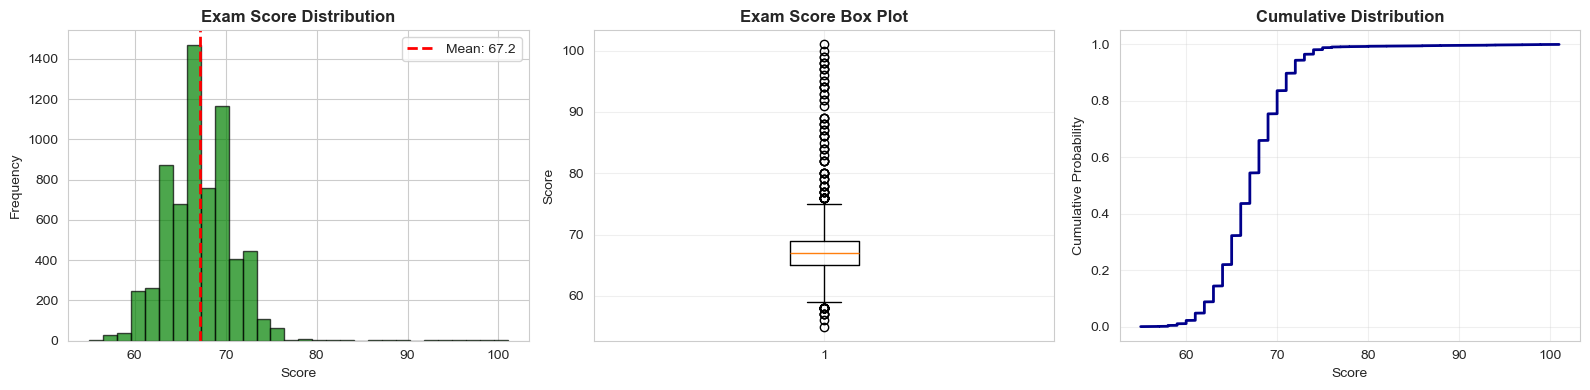

✓ Saved: data_target_analysis.png

Exam Score Statistics:
  Mean: 67.24
  Median: 67.00
  Std Dev: 3.89
  Min: 55
  Max: 101


In [13]:
# Target variable analysis
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Histogram
axes[0].hist(df['Exam_Score'], bins=30, color='green', alpha=0.7, edgecolor='black')
axes[0].set_title('Exam Score Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Score')
axes[0].set_ylabel('Frequency')
axes[0].axvline(df['Exam_Score'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df["Exam_Score"].mean():.1f}')
axes[0].legend()

# Box plot
axes[1].boxplot(df['Exam_Score'], vert=True)
axes[1].set_title('Exam Score Box Plot', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Score')
axes[1].grid(True, alpha=0.3)

# Cumulative distribution
sorted_scores = np.sort(df['Exam_Score'])
cumulative = np.arange(1, len(sorted_scores) + 1) / len(sorted_scores)
axes[2].plot(sorted_scores, cumulative, linewidth=2, color='darkblue')
axes[2].set_title('Cumulative Distribution', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Score')
axes[2].set_ylabel('Cumulative Probability')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/data_target_analysis.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: data_target_analysis.png")
print(f"\nExam Score Statistics:")
print(f"  Mean: {df['Exam_Score'].mean():.2f}")
print(f"  Median: {df['Exam_Score'].median():.2f}")
print(f"  Std Dev: {df['Exam_Score'].std():.2f}")
print(f"  Min: {df['Exam_Score'].min()}")
print(f"  Max: {df['Exam_Score'].max()}")

### 5. Data Overview Summary

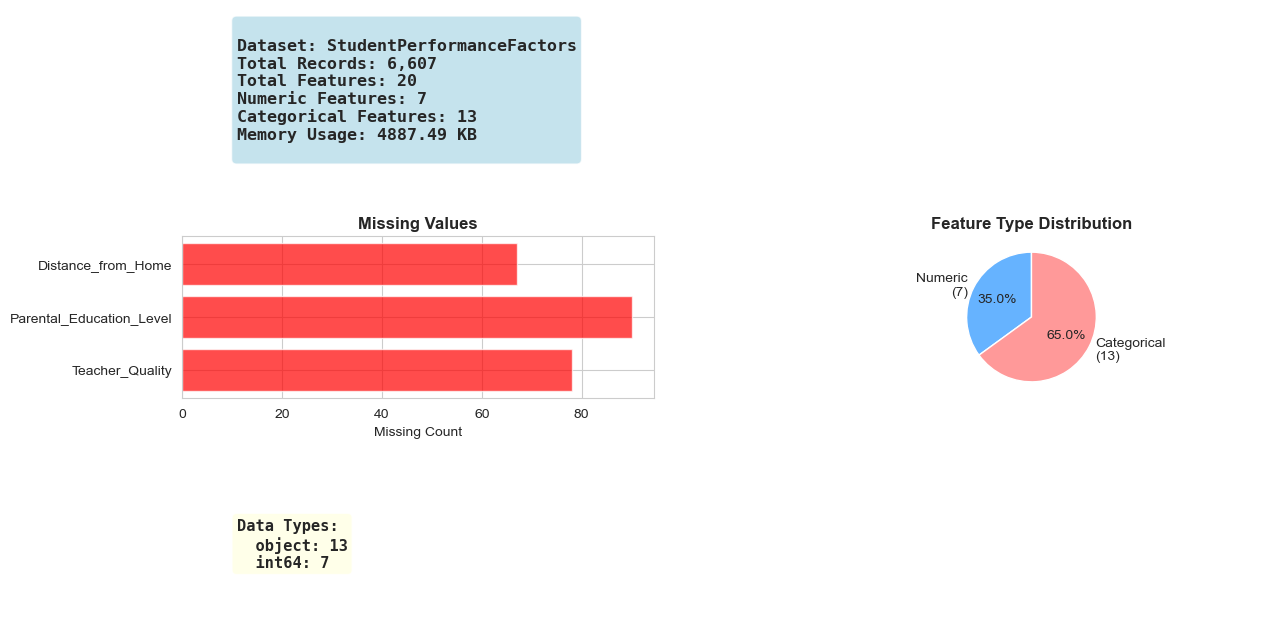

✓ Saved: data_overview_summary.png

ALL VISUALIZATIONS COMPLETED SUCCESSFULLY!


In [14]:
# Create a comprehensive info summary visualization
fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(3, 2, hspace=0.4, wspace=0.3)

# Dataset info text
ax1 = fig.add_subplot(gs[0, :])
ax1.axis('off')
info_text = f"""
Dataset: StudentPerformanceFactors
Total Records: {len(df):,}
Total Features: {len(df.columns)}
Numeric Features: {len(numeric_cols)}
Categorical Features: {len(categorical_cols)}
Memory Usage: {df.memory_usage(deep=True).sum() / 1024:.2f} KB
"""
ax1.text(0.05, 0.5, info_text, fontsize=12, verticalalignment='center',
         bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.7),
         family='monospace', fontweight='bold')

# Missing values
ax2 = fig.add_subplot(gs[1, 0])
missing = df.isnull().sum()
if missing.sum() > 0:
    ax2.barh(missing[missing > 0].index, missing[missing > 0].values, color='red', alpha=0.7)
    ax2.set_xlabel('Missing Count')
else:
    ax2.text(0.5, 0.5, 'No Missing Values', ha='center', va='center', fontsize=14, fontweight='bold')
ax2.set_title('Missing Values', fontsize=12, fontweight='bold')

# Feature count pie chart
ax3 = fig.add_subplot(gs[1, 1])
sizes = [len(numeric_cols), len(categorical_cols)]
labels = [f'Numeric\n({len(numeric_cols)})', f'Categorical\n({len(categorical_cols)})']
colors = ['#66b3ff', '#ff9999']
ax3.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=90)
ax3.set_title('Feature Type Distribution', fontsize=12, fontweight='bold')

# Data types summary
ax4 = fig.add_subplot(gs[2, :])
ax4.axis('off')
dtype_info = df.dtypes.value_counts()
dtype_text = "Data Types:\n" + "\n".join([f"  {dtype}: {count}" for dtype, count in dtype_info.items()])
ax4.text(0.05, 0.5, dtype_text, fontsize=11, verticalalignment='center',
         bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.7),
         family='monospace', fontweight='bold')

plt.savefig('outputs/data_overview_summary.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: data_overview_summary.png")
print("\n" + "="*60)
print("ALL VISUALIZATIONS COMPLETED SUCCESSFULLY!")
print("="*60)